Exercise 11.1 (Load the data with gaps and get rid of outliers)
Download and load the dataset. It has three columns: Date , pieces and pieces_gaps . The column pieces
contains the full data set without gaps, while pieces_gaps contains the same data set with several missing
values (NaNs). The period covered by the data set is from 2005-01-01 to 2024-12-31 in weekly frequency.
Visualize both time series ( pieces and pieces_gaps ) using the provided plot_production_data function.
Smooth the pieces_gaps time series using a rolling window with appropriate window size and decide whether it
is better to use mean or median as aggregation function. Discuss your choice. Ideally the resulting smoothed
time series should have the same gaps as the original pieces_gaps time series.
Visualize the resulting smoothed time series using seaborn .


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Lädt den Produktionsdatensatz aus dem Vorlesungsskript.
url = "https://noxthot.github.io/ws26_industrial_datascience_manuscript/data/assets/act1/selfstudysessions/sss1_production_data.csv"

df = pd.read_csv(url, parse_dates=["Date"])

# Verwendet das Datum als Zeitindex.
df = df.set_index("Date")




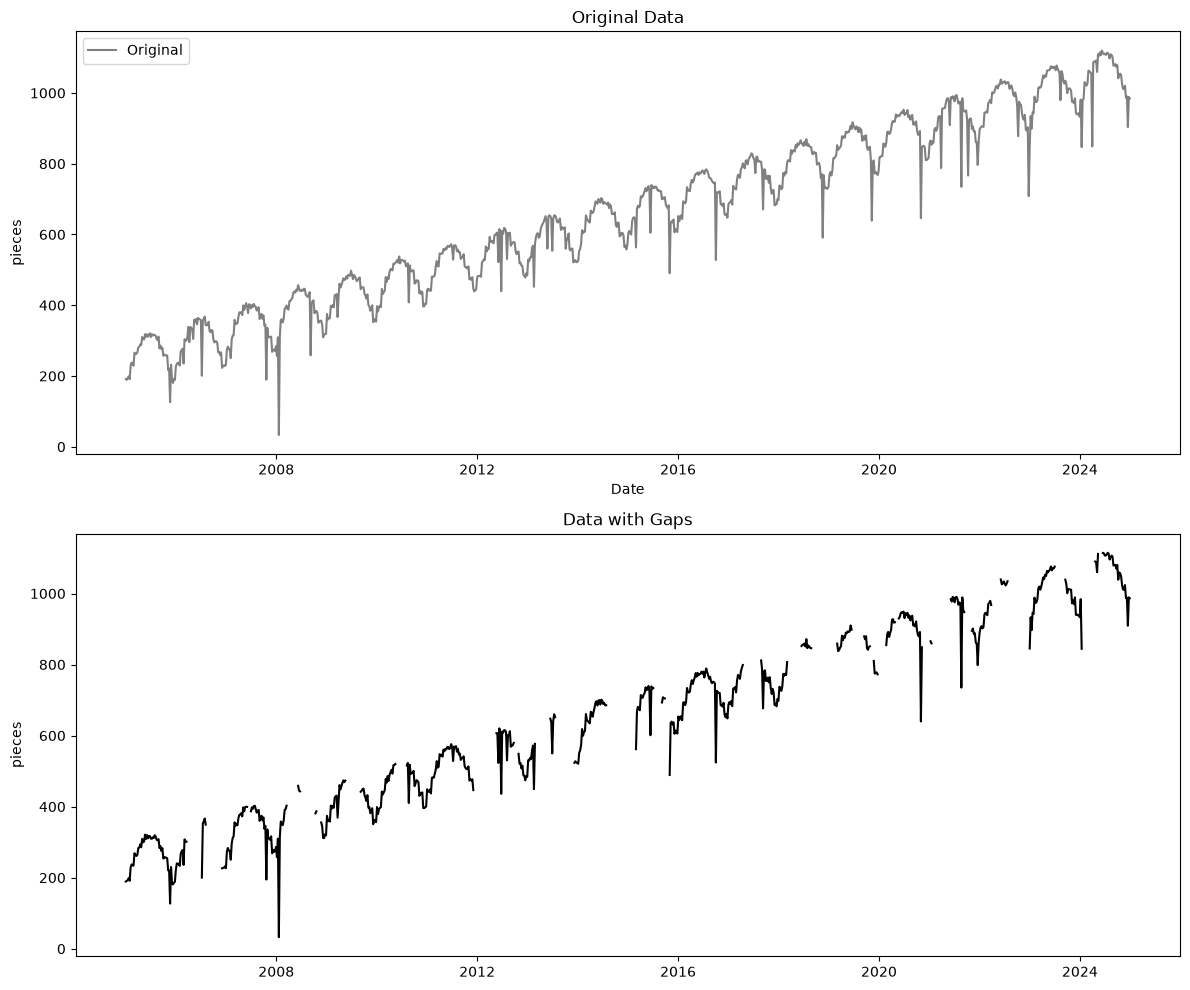

In [11]:
def plot_production_data(df, orig_data_column, gap_column, imp_column=None):

    # Erstellt zwei Diagramme untereinander.
    fig, axes = plt.subplots(3 if imp_column else 2, 1, figsize=(12, 10))

    # Zeigt die vollständige Produktionszeitreihe.
    sns.lineplot(
        x=df.index,
        y=df[orig_data_column],
        ax=axes[0],
        color="grey",
        label="Original"
    )

    axes[0].set_title("Original Data")
    axes[0].set_ylabel("pieces")

    # Zeigt die Produktionszeitreihe mit sichtbaren Datenlücken.
    # Matplotlib unterbricht die Linie automatisch bei NaN-Werten.
    axes[1].plot(
        df.index,
        df[gap_column],
        color="black",
        label="With Gaps"
    )

    axes[1].set_title("Data with Gaps")
    axes[1].set_ylabel("pieces")

    # Optionale Darstellung der imputierten Werte für spätere Übungen.
    if imp_column is not None:
        dff = df[[gap_column, imp_column]].copy()
        dff.loc[~df[gap_column].isna(), imp_column] = None

        sns.lineplot(
            x=dff.index,
            y=dff[imp_column],
            ax=axes[2],
            color="blue",
            label="Imputed"
        )

        axes[2].set_title("Imputed Data")
        axes[2].set_ylabel("pieces")

    plt.tight_layout()
    plt.show()


# Stellt die ursprüngliche Zeitreihe und die Zeitreihe mit Lücken dar.
plot_production_data(df, "pieces", "pieces_gaps")



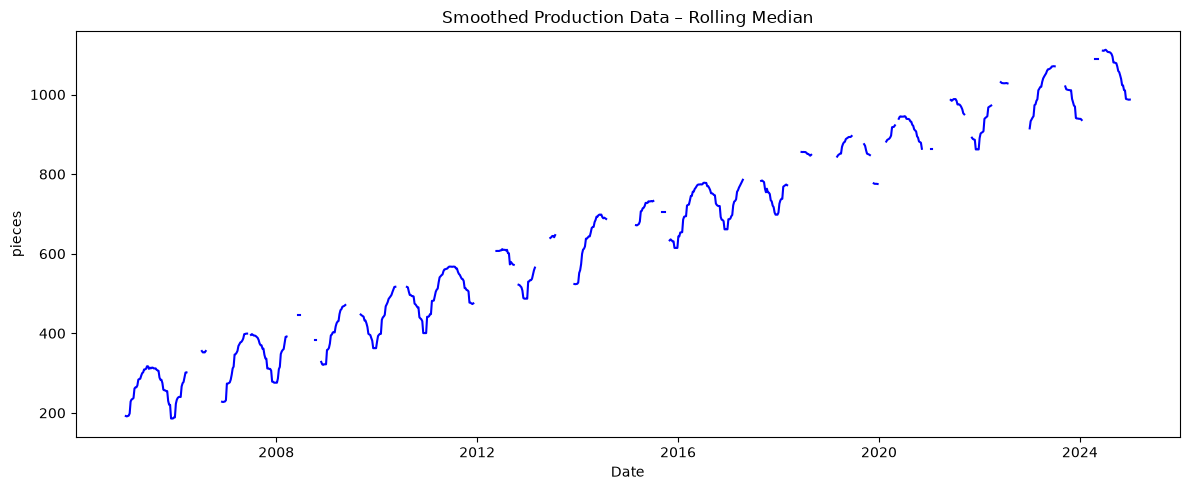

In [12]:
# Median Imputation
# Glättet die Zeitreihe mit einem zentrierten Rolling Median.
df["pieces_smoothed"] = (
    df["pieces_gaps"]
    .rolling(window=7, center=True, min_periods=2)
    .median()
)

# Erhält die ursprünglichen Datenlücken.
df.loc[df["pieces_gaps"].isna(), "pieces_smoothed"] = float("nan")

# Erstellt ein Diagramm für die geglättete Produktionszeitreihe.
plt.figure(figsize=(12, 5))

# Zeichnet die gültigen Messwerte mit Seaborn.
# Zusammenhängende Bereiche werden getrennt geplottet,
# damit die ursprünglichen Datenlücken sichtbar bleiben.
valid = df["pieces_smoothed"].notna()
segments = valid.ne(valid.shift()).cumsum()

for _, segment in df.groupby(segments):
    if segment["pieces_smoothed"].notna().all():
        sns.lineplot(
            x=segment.index,
            y=segment["pieces_smoothed"],
            color="blue",
            estimator=None
        )

plt.title("Smoothed Production Data – Rolling Median")
plt.xlabel("Date")
plt.ylabel("pieces")
plt.tight_layout()
plt.show()

In [13]:
# Berechnet den gleitenden Mittelwert.
df["pieces_mean"] = (
    df["pieces_gaps"]
    .rolling(window=7, center=True, min_periods=2)
    .mean()
)

# Berechnet den gleitenden Median.
df["pieces_median"] = (
    df["pieces_gaps"]
    .rolling(window=7, center=True, min_periods=2)
    .median()
)

# Behält die ursprünglichen Datenlücken bei.
df.loc[df["pieces_gaps"].isna(), ["pieces_mean", "pieces_median"]] = float("nan")

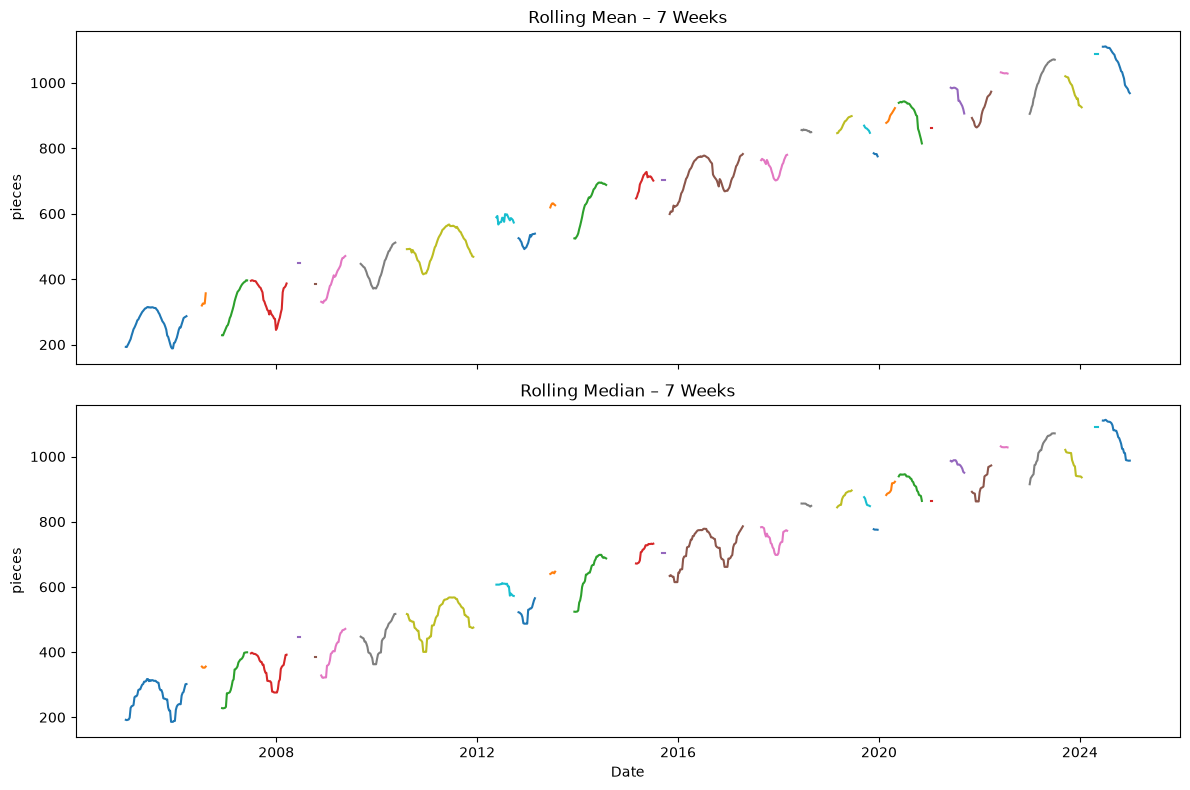

In [14]:
# Erstellt zwei Diagramme zum Vergleich.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Stellt Rolling Mean und Rolling Median getrennt dar.
columns = ["pieces_mean", "pieces_median"]
titles = ["Rolling Mean – 7 Weeks", "Rolling Median – 7 Weeks"]

for ax, column, title in zip(axes, columns, titles):

    # Identifiziert zusammenhängende Abschnitte ohne Datenlücken.
    valid = df[column].notna()
    segments = valid.ne(valid.shift()).cumsum()

    # Zeichnet die gültigen Abschnitte mit Seaborn.
    for _, segment in df.groupby(segments):
        if segment[column].notna().all():
            sns.lineplot(
                x=segment.index,
                y=segment[column],
                ax=ax,
                estimator=None
            )

    ax.set_title(title)
    ax.set_ylabel("pieces")

axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()